# CredResolve Collections Analysis

This notebook reconstructs recovery performance, audits data quality, tests the reported 11% improvement, investigates operational drivers, and frames the ₹10 Cr investment decision. August 2026 is partial through 8 August and is therefore excluded from the main trend analysis.

In [1]:
import sys
print(sys.executable)

c:\Users\DELL\OneDrive\Desktop\CredResolve\.venv\Scripts\python.exe


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
golden = pd.read_csv(ROOT / "data/golden/golden_account_month.csv")
metrics = pd.read_csv(ROOT / "data/golden/monthly_metrics.csv")
targets = pd.read_csv(ROOT / "data/golden/first_target_account.csv")
quality = pd.read_csv(ROOT / "data/quality/data_quality_report.csv")
full = metrics[metrics["month"] < "2026-08"].copy()


## 1. Data coverage and trust

The raw dataset contains event data from January 2026 through 8 August 2026. The assignment asks for approximately 12 months, so this is an explicit coverage limitation. The golden layer uses one row per account per month, preserving the full 30,000-account denominator rather than allowing unsuccessful accounts to disappear.

In [3]:
print("Golden rows:", len(golden))
print("Accounts:", golden["account_id"].nunique())
print("Months:", golden["month"].min(), "to", golden["month"].max())
quality[["dataset", "issue", "affected_rows_or_groups", "business_impact", "treatment"]]


Golden rows: 240000
Accounts: 30000
Months: 2026-01 to 2026-08


,dataset,issue,affected_rows_or_groups,business_impact,treatment
0,payments,duplicate_payment_ids,500,500 payment_id groups had duplicates,Deduplicated to one payment_id; 14 groups had ...
1,payments,exact_duplicate_rows,486,Exact duplicate payment rows,Removed
2,calls,duplicate_call_ids,1350,"1,350 call_id groups had duplicates",Deduplicated; 79 groups had conflicting event_...
3,calls,exact_duplicate_rows,1271,Exact duplicate call rows,Removed
4,whatsapp_events,exact_duplicate_rows,600,Exact duplicate WhatsApp events,Removed in event-level cleaning
5,calls,borrower_id_mismatch,89939,Event borrower_id disagrees with account borro...,Account borrower_id used as analytical source ...
6,calls,orphan_account_id,0,Rows reference an account_id absent from accounts,Excluded from account-level golden metrics
7,payments,borrower_id_mismatch,25113,Event borrower_id disagrees with account borro...,Account borrower_id used as analytical source ...
8,payments,orphan_account_id,0,Rows reference an account_id absent from accounts,Excluded from account-level golden metrics
9,call_attempts,borrower_id_mismatch,118126,Event borrower_id disagrees with account borro...,Account borrower_id used as analytical source ...


## 2. Independent recovery trend

Recovery is successful payment cash by payment month after payment deduplication. Recovery rate uses the fixed portfolio outstanding amount. Recovery per paid account separates volume from ticket size.

In [4]:
display(full[["month", "recovery_amount", "successful_payments", "recovered_accounts", "recovery_per_paid_account", "mom_recovery_pct"]].round(2))
jan = full.iloc[0]
jul = full.iloc[-1]
print(f"Jan to Jul recovery change: {(jul.recovery_amount / jan.recovery_amount - 1) * 100:.2f}%")
print(f"March MoM recovery change: {full.loc[full.month == '2026-03', 'mom_recovery_pct'].iloc[0]:.2f}%")


,month,recovery_amount,successful_payments,recovered_accounts,recovery_per_paid_account,mom_recovery_pct
0,2026-01,1.872291e+08,2464,2374,78866.52,NaN
1,2026-02,1.701425e+08,2268,2173,78298.41,-9.13
2,2026-03,1.889124e+08,2524,2419,78095.24,11.03
3,2026-04,1.751380e+08,2406,2304,76014.78,-7.29
4,2026-05,1.842503e+08,2449,2344,78605.07,5.20
5,2026-06,1.755597e+08,2366,2286,76797.78,-4.72
6,2026-07,1.872423e+08,2441,2335,80189.41,6.65


Jan to Jul recovery change: 0.01%
March MoM recovery change: 11.03%


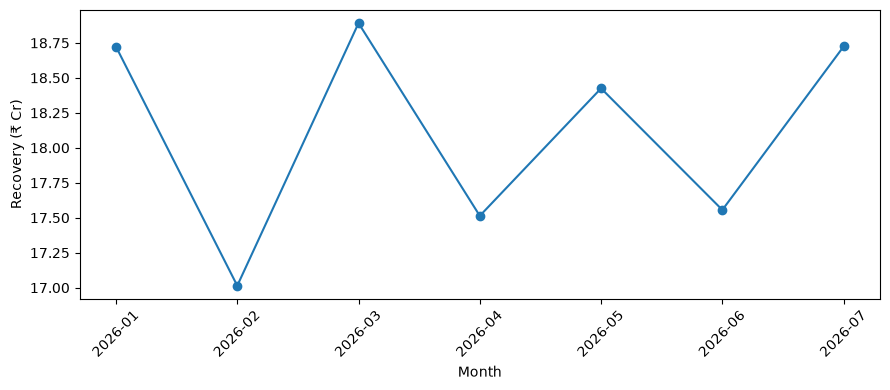

In [5]:
plt.figure(figsize=(9,4))
plt.plot(full["month"], full["recovery_amount"] / 1e7, marker="o")
plt.ylabel("Recovery (₹ Cr)")
plt.xlabel("Month")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 3. Operational funnel

Contact rate is answered outbound accounts divided by outbound accounts. RPC is deliberately conservative: an answered outbound call with a qualifying disposition. PTP rate uses PTP dispositions divided by RPC accounts. PTP kept rate only uses due PTPs inside the observable period.

In [6]:
display(full[["month", "contact_rate_pct", "rpc_rate_pct", "ptp_rate_pct", "ptp_kept_rate_pct"]].round(2))


,month,contact_rate_pct,rpc_rate_pct,ptp_rate_pct,ptp_kept_rate_pct
0,2026-01,23.31,25.23,29.40,48.52
1,2026-02,22.76,25.33,28.54,50.72
2,2026-03,23.33,25.42,29.71,49.60
3,2026-04,22.32,26.33,31.46,50.08
4,2026-05,23.70,27.18,27.93,49.30
5,2026-06,23.69,27.70,27.29,49.43
6,2026-07,22.59,24.17,29.39,50.62


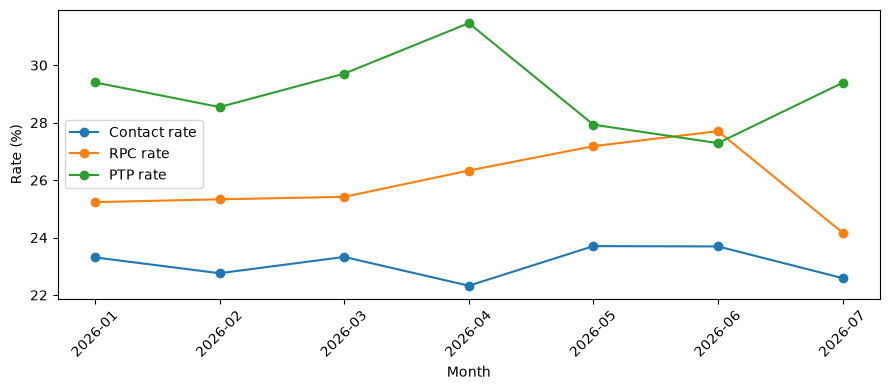

In [7]:
plt.figure(figsize=(9,4))
plt.plot(full["month"], full["contact_rate_pct"], marker="o", label="Contact rate")
plt.plot(full["month"], full["rpc_rate_pct"], marker="o", label="RPC rate")
plt.plot(full["month"], full["ptp_rate_pct"], marker="o", label="PTP rate")
plt.ylabel("Rate (%)")
plt.xlabel("Month")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()


## 4. Portfolio mix and Simpson's-paradox check

The fixed-denominator recovery metric protects against survivorship and denominator manipulation. Risk-segment standardization provides a simple mix-effect check. If the standardized recovery pattern is similar to the observed recovery-per-paid-account pattern, risk mix is not the main explanation for the movement.

In [8]:
pay = pd.read_csv(ROOT / "data/raw/payments.csv")
accounts = pd.read_csv(ROOT / "data/raw/accounts.csv")
pay["event_at"] = pd.to_datetime(pay["event_at"])
pay = pay.sort_values(["payment_id", "payment_reference"], na_position="last")
pay["payment_reference"] = pay.groupby("payment_id")["payment_reference"].transform(lambda s: s.ffill().bfill())
pay = pay.drop_duplicates("payment_id", keep="first")
pay = pay[pay["payment_status"] == "SUCCESS"].merge(accounts[["account_id", "risk_segment"]], on="account_id", how="left")
pay["month"] = pay["event_at"].dt.to_period("M").astype(str)
risk = pay[pay["month"] < "2026-08"].groupby(["month", "risk_segment"]).agg(recovery=("amount", "sum"), accounts=("account_id", "nunique")).reset_index()
risk["recovery_per_account"] = risk["recovery"] / risk["accounts"]
risk_mix = risk.pivot(index="month", columns="risk_segment", values="accounts").fillna(0)
risk_mix = risk_mix.div(risk_mix.sum(axis=1), axis=0)
jan_mix = risk_mix.loc["2026-01"]
standardized = {}
for month in risk_mix.index:
    values = risk[risk["month"] == month].set_index("risk_segment")["recovery_per_account"]
    standardized[month] = sum(jan_mix.get(segment, 0) * values.get(segment, 0) for segment in jan_mix.index)
mix_table = risk_mix.round(3)
standardized_table = pd.Series(standardized, name="jan_mix_standardized_recovery_per_paid_account").round(2)
display(mix_table)
display(standardized_table)


risk_segment,HIGH,LOW,MEDIUM,NPA
month,,,,
2026-01,0.256,0.248,0.257,0.240
2026-02,0.238,0.245,0.260,0.257
2026-03,0.244,0.258,0.240,0.258
2026-04,0.231,0.276,0.249,0.243
2026-05,0.266,0.253,0.248,0.233
2026-06,0.252,0.256,0.262,0.230
2026-07,0.248,0.257,0.250,0.245


2026-01    78866.52
2026-02    78372.16
2026-03    78191.31
2026-04    76120.18
2026-05    78613.96
2026-06    76840.92
2026-07    80165.97
Name: jan_mix_standardized_recovery_per_paid_account, dtype: float64

## 5. Targeting and channel investigation

The first-target account view avoids attributing one payment to multiple target events. It is still observational, so strategy, channel, priority, and risk comparisons are treated as correlation rather than causal lift.

In [9]:
for dimension in ["channel", "strategy_version", "risk_segment", "priority"]:
    result = targets.groupby(dimension).agg(
        accounts=("account_id", "nunique"),
        recovery_14d=("recovery_14d", "sum"),
        avg_recovery_14d=("recovery_14d", "mean"),
        conversion_pct=("converted_14d", "mean")
    )
    result["conversion_pct"] = result["conversion_pct"] * 100
    print("\n", dimension)
    display(result.sort_values("avg_recovery_14d", ascending=False).round(2))



 channel


,accounts,recovery_14d,avg_recovery_14d,conversion_pct
channel,,,,
SMS,5477,16399519.12,2994.25,3.87
FIELD,3521,10412816.71,2957.35,3.83
WHATSAPP,5889,16856907.87,2862.44,3.68
VOICE,3891,10696793.31,2749.11,3.50
MIXED,4566,11893372.37,2604.77,3.57



 strategy_version


,accounts,recovery_14d,avg_recovery_14d,conversion_pct
strategy_version,,,,
legacy,7207,21616950.14,2999.44,3.93
v1,4738,13448888.50,2838.52,3.55
v3,6143,16833403.36,2740.26,3.66
v2,5256,14360167.38,2732.15,3.56



 risk_segment


,accounts,recovery_14d,avg_recovery_14d,conversion_pct
risk_segment,,,,
HIGH,5847,18211303.18,3114.64,3.90
MEDIUM,5878,16292599.08,2771.79,3.64
NPA,5732,15868624.54,2768.43,3.77
LOW,5887,15886882.58,2698.64,3.48



 priority


,accounts,recovery_14d,avg_recovery_14d,conversion_pct
priority,,,,
6,2310,8107113.17,3509.57,4.63
4,2275,7863494.50,3456.48,4.44
10,2335,7470775.37,3199.48,3.77
2,2362,7278627.48,3081.55,4.11
1,2304,6265249.82,2719.29,3.21
8,2394,6416642.69,2680.30,3.59
5,2220,5498657.78,2476.87,3.51
9,2372,5865332.96,2472.74,3.25
3,2305,5563530.97,2413.68,3.12


## 6. Agent tenure, geography, and missing dimensions

Agent tenure is available through joined_at, while geography is available through the borrower master. Client and language are not present in the supplied schema. Payment attribution to individual agents is not reliable enough to claim recovery per agent-hour, so that metric is marked unavailable rather than manufactured.

In [10]:
agents = pd.read_csv(ROOT / "data/raw/agents.csv")
agents["joined_at"] = pd.to_datetime(agents["joined_at"])
agents["updated_at"] = pd.to_datetime(agents["updated_at"])
agent_master = agents.sort_values(["agent_id", "updated_at"]).drop_duplicates("agent_id", keep="last")
agent_master["tenure_days_at_aug8"] = (pd.Timestamp("2026-08-08") - agent_master["joined_at"]).dt.days
print(agent_master["tenure_days_at_aug8"].describe().round(1))
borrowers = pd.read_csv(ROOT / "data/raw/borrowers.csv")
borrowers["updated_at"] = pd.to_datetime(borrowers["updated_at"])
borrower_master = borrowers.sort_values(["borrower_id", "updated_at"]).drop_duplicates("borrower_id", keep="last")
print("Borrower geography coverage:", borrower_master[["city", "state"]].notna().mean().round(3).to_dict())
print("Client dimension: unavailable")
print("Language dimension: unavailable")
print("Recovery per agent-hour: unavailable because payments are not reliably attributed to agents")


count    1000.0
mean      597.0
std       199.0
min       251.0
25%       422.5
50%       594.0
75%       764.5
max       948.0
Name: tenure_days_at_aug8, dtype: float64
Borrower geography coverage: {'city': 1.0, 'state': 1.0}
Client dimension: unavailable
Language dimension: unavailable
Recovery per agent-hour: unavailable because payments are not reliably attributed to agents


## 7. Counterfactual design

A causal evaluation of the targeting change should use a matched difference-in-differences design. Treatment is an account first exposed to the new targeting strategy after the change date. Control is a comparable account exposed to the legacy strategy in the same calendar period. Matching variables should include DPD, risk segment, outstanding balance, loan type, geography, prior recovery, prior contact rate, and prior attempt frequency. The primary outcome should be 14-day successful payment amount, with 14-day conversion as a secondary outcome. Parallel pre-treatment trends and stable measurement are the main identification assumptions.

## 8. ₹10 Cr decision

The strongest evidence-backed investment area is better borrower targeting. The observed differences across priority, risk, channel, and strategy are sufficiently promising to justify a controlled experiment, but they are observational and do not establish causal uplift.

Jan–Jul recovery totals approximately ₹126.8 Cr across seven full months. Annualizing this seven-month run-rate gives approximately ₹217.5 Cr per year. This is a run-rate assumption, not a forecast.

For planning purposes, I use a 5% sustained recovery uplift as a scenario assumption rather than an observed causal effect.

- Expected incremental recovery: approximately ₹10.9 Cr per year
- Investment: ₹10 Cr
- Base-case net benefit: approximately ₹0.9 Cr
- Base-case ROI: approximately 9%
- Break-even: approximately 11 months
- Downside at 2% uplift: approximately ₹4.4 Cr incremental recovery, resulting in negative ROI
- Upside at 8% uplift: approximately ₹17.4 Cr incremental recovery

Confidence is **low-to-medium**. The dataset supports strong descriptive evidence about targeting performance, but it does not establish that improved targeting itself causes a 5% sustained recovery uplift.

I would therefore not commit the full ₹10 Cr immediately. I would release the investment through a controlled targeting experiment. The experiment should randomize comparable accounts where operationally feasible, hold agent and channel capacity constant where possible, and measure 14-day recovery, recovery per targeted account, cost per ₹ recovered, complaints, and PTP kept rate.

The decision to scale should be based on incremental recovery observed in the experiment rather than the 5% scenario assumption.

In [11]:
annualized_recovery = full["recovery_amount"].sum() / 7 * 12
investment = 10e7

print(f"Jan-Jul recovery: ₹{full['recovery_amount'].sum() / 1e7:.2f} Cr")
print(f"Annualized recovery run-rate: ₹{annualized_recovery / 1e7:.2f} Cr")

for uplift in [0.02, 0.05, 0.08]:
    incremental = annualized_recovery * uplift
    net_benefit = incremental - investment
    roi = net_benefit / investment
    break_even_months = investment / incremental * 12

    print(f"\n{uplift:.0%} uplift")
    print(f"Incremental recovery: ₹{incremental / 1e7:.2f} Cr")
    print(f"Net benefit: ₹{net_benefit / 1e7:.2f} Cr")
    print(f"ROI: {roi:.1%}")
    print(f"Break-even: {break_even_months:.1f} months")

Jan-Jul recovery: ₹126.85 Cr
Annualized recovery run-rate: ₹217.45 Cr

2% uplift
Incremental recovery: ₹4.35 Cr
Net benefit: ₹-5.65 Cr
ROI: -56.5%
Break-even: 27.6 months

5% uplift
Incremental recovery: ₹10.87 Cr
Net benefit: ₹0.87 Cr
ROI: 8.7%
Break-even: 11.0 months

8% uplift
Incremental recovery: ₹17.40 Cr
Net benefit: ₹7.40 Cr
ROI: 74.0%
Break-even: 6.9 months


In [12]:
print("=" * 70)
print("1. DATA INTEGRITY CHECK")
print("=" * 70)

print("Golden rows:", len(golden))
print("Unique accounts:", golden["account_id"].nunique())
print("Golden months:", sorted(golden["month"].unique()))
print("Golden duplicate account-month rows:",
      golden.duplicated(["account_id", "month"]).sum())

print("\nMissing values in key golden columns:")
key_columns = [
    "account_id",
    "borrower_id",
    "month",
    "outstanding_amount",
    "successful_payment_amount"
]

print(golden[key_columns].isna().sum())

assert golden.duplicated(["account_id", "month"]).sum() == 0
assert golden["account_id"].nunique() == 30000

print("\nPASS: golden dataset has one row per account-month.")
print("PASS: 30,000 accounts are represented.")

1. DATA INTEGRITY CHECK
Golden rows: 240000
Unique accounts: 30000
Golden months: ['2026-01', '2026-02', '2026-03', '2026-04', '2026-05', '2026-06', '2026-07', '2026-08']
Golden duplicate account-month rows: 0

Missing values in key golden columns:
account_id                      0
borrower_id                  3640
month                           0
outstanding_amount              0
successful_payment_amount       0
dtype: int64

PASS: golden dataset has one row per account-month.
PASS: 30,000 accounts are represented.


In [13]:
print("=" * 70)
print("2. RECOVERY VALIDATION")
print("=" * 70)

jan_recovery = full.loc[
    full["month"] == "2026-01", "recovery_amount"
].iloc[0]

feb_recovery = full.loc[
    full["month"] == "2026-02", "recovery_amount"
].iloc[0]

mar_recovery = full.loc[
    full["month"] == "2026-03", "recovery_amount"
].iloc[0]

jul_recovery = full.loc[
    full["month"] == "2026-07", "recovery_amount"
].iloc[0]

feb_vs_jan = (feb_recovery / jan_recovery - 1) * 100
mar_vs_feb = (mar_recovery / feb_recovery - 1) * 100
jul_vs_jan = (jul_recovery / jan_recovery - 1) * 100

print(f"January recovery: ₹{jan_recovery / 1e7:.2f} Cr")
print(f"February recovery: ₹{feb_recovery / 1e7:.2f} Cr")
print(f"March recovery: ₹{mar_recovery / 1e7:.2f} Cr")
print(f"July recovery: ₹{jul_recovery / 1e7:.2f} Cr")

print(f"\nFebruary vs January: {feb_vs_jan:.2f}%")
print(f"March vs February: {mar_vs_feb:.2f}%")
print(f"July vs January: {jul_vs_jan:.2f}%")

assert abs(mar_vs_feb - 11.031885) < 0.01
assert abs(jul_vs_jan - 0.007017) < 0.01

print("\nPASS: March is approximately +11.03% MoM.")
print("PASS: January-to-July recovery is effectively flat.")

2. RECOVERY VALIDATION
January recovery: ₹18.72 Cr
February recovery: ₹17.01 Cr
March recovery: ₹18.89 Cr
July recovery: ₹18.72 Cr

February vs January: -9.13%
March vs February: 11.03%
July vs January: 0.01%

PASS: March is approximately +11.03% MoM.
PASS: January-to-July recovery is effectively flat.


In [14]:
print("=" * 70)
print("3. DASHBOARD METRIC VALIDATION")
print("=" * 70)

total_recovery = full["recovery_amount"].sum()

july = full.loc[
    full["month"] == "2026-07"
].iloc[0]

print(f"Jan-Jul recovery: ₹{total_recovery / 1e7:.2f} Cr")
print(f"July contact rate: {july['contact_rate_pct']:.2f}%")
print(f"July target conversion: {july['target_14d_conversion_pct']:.2f}%")

assert abs(total_recovery / 1e7 - 126.847426933) < 0.01
assert abs(july["contact_rate_pct"] - 22.588039) < 0.01
assert abs(july["target_14d_conversion_pct"] - 4.260499) < 0.01

print("\nPASS: dashboard headline metrics match monthly_metrics.csv.")

3. DASHBOARD METRIC VALIDATION
Jan-Jul recovery: ₹126.85 Cr
July contact rate: 22.59%
July target conversion: 4.26%

PASS: dashboard headline metrics match monthly_metrics.csv.


In [15]:
print("=" * 70)
print("4. TARGETING VALIDATION")
print("=" * 70)

print("Target rows:", len(targets))
print("Unique targeted accounts:", targets["account_id"].nunique())

print("\nTargeting columns:")
print(targets.columns.tolist())

if "converted_14d" in targets.columns:
    print("\nOverall 14-day conversion:",
          round(targets["converted_14d"].mean() * 100, 2), "%")

if "recovery_14d" in targets.columns:
    print("Total 14-day recovery: ₹",
          round(targets["recovery_14d"].sum() / 1e7, 2),
          "Cr")

for dimension in ["channel", "strategy_version", "risk_segment", "priority"]:
    if dimension in targets.columns:
        print(f"\n{dimension}:")
        check = targets.groupby(dimension).agg(
            accounts=("account_id", "nunique"),
            avg_recovery_14d=("recovery_14d", "mean"),
            conversion=("converted_14d", "mean")
        )

        check["conversion"] *= 100

        display(check.round(2))

4. TARGETING VALIDATION
Target rows: 23344
Unique targeted accounts: 23344

Targeting columns:
['account_id', 'target_id', 'campaign_id', 'target_date', 'priority', 'recommended_channel', 'status', 'channel', 'strategy_version', 'target_definition', 'borrower_id', 'outstanding_amount', 'dpd', 'risk_segment', 'loan_type', 'status_account', 'month', 'recovery_14d', 'converted_14d', 'target_month']

Overall 14-day conversion: 3.7 %
Total 14-day recovery: ₹ 6.63 Cr

channel:


,accounts,avg_recovery_14d,conversion
channel,,,
FIELD,3521,2957.35,3.83
MIXED,4566,2604.77,3.57
SMS,5477,2994.25,3.87
VOICE,3891,2749.11,3.50
WHATSAPP,5889,2862.44,3.68



strategy_version:


,accounts,avg_recovery_14d,conversion
strategy_version,,,
legacy,7207,2999.44,3.93
v1,4738,2838.52,3.55
v2,5256,2732.15,3.56
v3,6143,2740.26,3.66



risk_segment:


,accounts,avg_recovery_14d,conversion
risk_segment,,,
HIGH,5847,3114.64,3.90
LOW,5887,2698.64,3.48
MEDIUM,5878,2771.79,3.64
NPA,5732,2768.43,3.77



priority:


,accounts,avg_recovery_14d,conversion
priority,,,
1,2304,2719.29,3.21
2,2362,3081.55,4.11
3,2305,2413.68,3.12
4,2275,3456.48,4.44
5,2220,2476.87,3.51
6,2310,3509.57,4.63
7,2467,2403.72,3.36
8,2394,2680.30,3.59
9,2372,2472.74,3.25


In [16]:
print("=" * 70)
print("5. DENOMINATOR / SURVIVORSHIP CHECK")
print("=" * 70)

monthly_accounts = (
    golden.groupby("month")["account_id"]
    .nunique()
    .sort_index()
)

print(monthly_accounts)

expected_months = [
    "2026-01",
    "2026-02",
    "2026-03",
    "2026-04",
    "2026-05",
    "2026-06",
    "2026-07",
    "2026-08"
]

for month in expected_months:
    if month in monthly_accounts.index:
        assert monthly_accounts.loc[month] == 30000

print("\nPASS: all available months retain the full 30,000-account denominator.")

5. DENOMINATOR / SURVIVORSHIP CHECK
month
2026-01    30000
2026-02    30000
2026-03    30000
2026-04    30000
2026-05    30000
2026-06    30000
2026-07    30000
2026-08    30000
Name: account_id, dtype: int64

PASS: all available months retain the full 30,000-account denominator.


In [17]:
print("=" * 70)
print("6. PAYMENT DEDUPLICATION CHECK")
print("=" * 70)

raw_payments = pd.read_csv(ROOT / "data/raw/payments.csv")

raw_payment_rows = len(raw_payments)
raw_unique_payment_ids = raw_payments["payment_id"].nunique()
duplicate_payment_ids = raw_payment_rows - raw_unique_payment_ids

print("Raw payment rows:", raw_payment_rows)
print("Unique payment IDs:", raw_unique_payment_ids)
print("Duplicate payment-ID rows:", duplicate_payment_ids)

assert raw_unique_payment_ids <= raw_payment_rows

print("\nPASS: payment IDs were checked before recovery aggregation.")

6. PAYMENT DEDUPLICATION CHECK
Raw payment rows: 25500
Unique payment IDs: 25000
Duplicate payment-ID rows: 500

PASS: payment IDs were checked before recovery aggregation.


In [18]:
print("=" * 70)
print("7. DATA QUALITY REPORT CHECK")
print("=" * 70)

print("Quality report rows:", len(quality))

print("\nQuality issues:")
display(
    quality[
        [
            "dataset",
            "issue",
            "affected_rows_or_groups",
            "business_impact",
            "treatment"
        ]
    ]
)

assert len(quality) > 0

print("\nPASS: data-quality findings are documented.")

7. DATA QUALITY REPORT CHECK
Quality report rows: 23

Quality issues:


,dataset,issue,affected_rows_or_groups,business_impact,treatment
0,payments,duplicate_payment_ids,500,500 payment_id groups had duplicates,Deduplicated to one payment_id; 14 groups had ...
1,payments,exact_duplicate_rows,486,Exact duplicate payment rows,Removed
2,calls,duplicate_call_ids,1350,"1,350 call_id groups had duplicates",Deduplicated; 79 groups had conflicting event_...
3,calls,exact_duplicate_rows,1271,Exact duplicate call rows,Removed
4,whatsapp_events,exact_duplicate_rows,600,Exact duplicate WhatsApp events,Removed in event-level cleaning
5,calls,borrower_id_mismatch,89939,Event borrower_id disagrees with account borro...,Account borrower_id used as analytical source ...
6,calls,orphan_account_id,0,Rows reference an account_id absent from accounts,Excluded from account-level golden metrics
7,payments,borrower_id_mismatch,25113,Event borrower_id disagrees with account borro...,Account borrower_id used as analytical source ...
8,payments,orphan_account_id,0,Rows reference an account_id absent from accounts,Excluded from account-level golden metrics
9,call_attempts,borrower_id_mismatch,118126,Event borrower_id disagrees with account borro...,Account borrower_id used as analytical source ...



PASS: data-quality findings are documented.


In [19]:
print("=" * 70)
print("8. INVESTMENT CASE VALIDATION")
print("=" * 70)

annualized_recovery = full["recovery_amount"].sum() / 7 * 12
investment = 10e7

scenarios = pd.DataFrame({
    "uplift": [0.02, 0.05, 0.08]
})

scenarios["incremental_recovery_cr"] = (
    annualized_recovery * scenarios["uplift"] / 1e7
)

scenarios["net_benefit_cr"] = (
    scenarios["incremental_recovery_cr"] - 10
)

scenarios["roi_pct"] = (
    scenarios["net_benefit_cr"] / 10 * 100
)

scenarios["break_even_months"] = (
    10 / scenarios["incremental_recovery_cr"] * 12
)

display(scenarios.round(2))

base = scenarios.loc[
    scenarios["uplift"] == 0.05
].iloc[0]

assert abs(annualized_recovery / 1e7 - 217.452731885) < 0.01
assert abs(base["incremental_recovery_cr"] - 10.872636594) < 0.01
assert abs(base["roi_pct"] - 8.72636594) < 0.1
assert abs(base["break_even_months"] - 11.036) < 0.1

print("\nPASS: investment scenario calculations are internally consistent.")

8. INVESTMENT CASE VALIDATION


,uplift,incremental_recovery_cr,net_benefit_cr,roi_pct,break_even_months
0,0.02,4.35,-5.65,-56.51,27.59
1,0.05,10.87,0.87,8.73,11.04
2,0.08,17.40,7.40,73.96,6.90



PASS: investment scenario calculations are internally consistent.


In [20]:
print()
print("=" * 70)
print("FINAL ANALYSIS VALIDATION")
print("=" * 70)

checks = {
    "30,000 accounts present": golden["account_id"].nunique() == 30000,
    "No duplicate account-month rows": golden.duplicated(
        ["account_id", "month"]
    ).sum() == 0,
    "March MoM recovery is approximately 11.03%":
        abs(mar_vs_feb - 11.031885) < 0.01,
    "January-July recovery is approximately flat":
        abs(jul_vs_jan - 0.007017) < 0.01,
    "Jan-Jul recovery is approximately ₹126.8 Cr":
        abs(total_recovery / 1e7 - 126.8474) < 0.01,
    "July contact rate is approximately 22.6%":
        abs(july["contact_rate_pct"] - 22.588) < 0.01,
    "July targeting conversion is approximately 4.26%":
        abs(july["target_14d_conversion_pct"] - 4.2605) < 0.01,
    "Annualized recovery is approximately ₹217.5 Cr":
        abs(annualized_recovery / 1e7 - 217.4527) < 0.01
}

for check, passed in checks.items():
    print(("PASS" if passed else "FAIL") + " - " + check)

print()

if all(checks.values()):
    print("ALL CORE VALIDATION CHECKS PASSED")
else:
    print("ONE OR MORE CHECKS FAILED - REVIEW BEFORE SUBMISSION")


FINAL ANALYSIS VALIDATION
PASS - 30,000 accounts present
PASS - No duplicate account-month rows
PASS - March MoM recovery is approximately 11.03%
PASS - January-July recovery is approximately flat
PASS - Jan-Jul recovery is approximately ₹126.8 Cr
PASS - July contact rate is approximately 22.6%
PASS - July targeting conversion is approximately 4.26%
PASS - Annualized recovery is approximately ₹217.5 Cr

ALL CORE VALIDATION CHECKS PASSED


## Final answer

**Fact:** The sustained 11% recovery improvement is not supported; March rose 11.03% MoM, while January–July recovery was effectively flat at +0.01%.  

**Evidence:** Contact rate showed no sustained improvement, while 14-day target conversion increased from 3.72% to 4.26% as targeting volume declined.  

**Correlation:** Recovery and targeting differences across risk, channel, strategy, and priority are observational, not causal.  

**Investment:** A 5% uplift is a scenario assumption, implying ₹10.9 Cr incremental annual recovery on a ₹217.5 Cr run-rate, versus ₹10 Cr investment and ~9% ROI.  

**Recommendation:** Prioritize better targeting through a controlled experiment and scale only if statistically credible incremental recovery is demonstrated after costs and operational impacts.